<a href="https://colab.research.google.com/github/CamilaHenaoIbero/Actividad4-Aprendizaje-No-Supervisado/blob/main/Actividad_4_Aprendizaje_No_Supervisado_ipynb_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Librerías importadas correctamente.
¡El dataset de transporte se ha generado y guardado exitosamente!

¡Modelo K-Means entrenado y grupos asignados con éxito!
Perfil de los centros de cada grupo detectado:
[[-1.14160332 -1.02505182  1.24603685]
 [-0.10245158 -0.28268119 -0.2184766 ]
 [ 1.22941896  1.26734998 -1.05877119]]


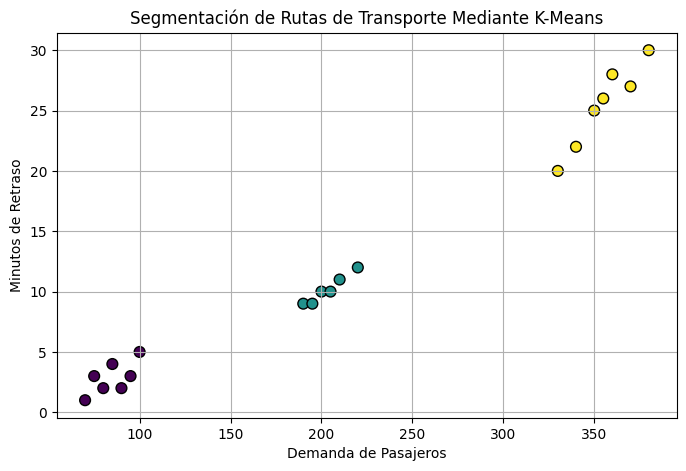


¡Proceso de agrupamiento finalizado y exportado correctamente!


In [1]:
# ==========================================
# Maria Camila Henao Toro
# Iberoamericana
# Inteligencia Artificial
# ==========================================
# ==========================================
# 1. IMPORTAR LIBRERÍAS
# ==========================================
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

print("Librerías importadas correctamente.")


# ========================================================
# 2. CREAR DATASET (SIMULADO) Y APLICAR APRENDIZAJE K-MEANS
# ========================================================

# Generamos y guardamos nuestro dataset con variables clave del transporte masivo
np.random.seed(42)
datos_simulados = {
    'Demanda_Pasajeros': [350, 80, 200, 380, 95, 210, 340, 70, 190, 360, 85, 220, 330, 90, 205, 370, 75, 195, 355, 100],
    'Minutos_Retraso': [25, 2, 10, 30, 3, 11, 22, 1, 9, 28, 4, 12, 20, 2, 10, 27, 3, 9, 26, 5],
    'Frecuencia_Bus': [4, 15, 8, 3, 14, 8, 5, 18, 9, 4, 16, 7, 5, 15, 8, 3, 17, 9, 4, 13]
}

df = pd.DataFrame(datos_simulados)
df.to_csv('dataset_transporte.csv', index=False)
print("¡El dataset de transporte se ha generado y guardado exitosamente!")

# Cargamos el archivo CSV para comenzar a procesar la información
df = pd.read_csv('dataset_transporte.csv')

# Seleccionamos las variables numéricas y aplicamos estandarización
# (Clave en K-Means para que todas las métricas tengan el mismo peso analítico)
X = df[['Demanda_Pasajeros', 'Minutos_Retraso', 'Frecuencia_Bus']]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Configuramos y entrenamos nuestro modelo no supervisado K-Means en 3 clústeres
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Grupo'] = kmeans.fit_predict(X_scaled)

print("\n¡Modelo K-Means entrenado y grupos asignados con éxito!")


# ==========================================
# 3. ANALIZAR CENTROIDES Y VISUALIZAR RESULTADOS
# ==========================================

# Imprimimos el perfil de los centros de cada grupo detectado
print("Perfil de los centros de cada grupo detectado:")
print(kmeans.cluster_centers_)

# Graficamos los resultados en una dispersión para visualizar los clústeres formados
plt.figure(figsize=(8, 5))
plt.scatter(df['Demanda_Pasajeros'], df['Minutos_Retraso'], c=df['Grupo'], cmap='viridis', s=60, edgecolors='k')
plt.title('Segmentación de Rutas de Transporte Mediante K-Means')
plt.xlabel('Demanda de Pasajeros')
plt.ylabel('Minutos de Retraso')
plt.grid(True)
plt.show()

# Guardamos el resultado final con los grupos asignados
df.to_csv('dataset_agrupado_transporte.csv', index=False)
print("\n¡Proceso de agrupamiento finalizado y exportado correctamente!")